# Example: What is the Extrinsic Value of an Option Contract?
In the lecture, we split an option's premium into intrinsic and extrinsic value. How large is each part for a real contract, and how does the extrinsic value change with the strike price and the time to expiration?

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Decompose option premiums into intrinsic and extrinsic values:__ Separate an option's premium into its immediate exercise value and its time value.
> * __Analyze how time to expiration affects extrinsic value:__ Measure how extrinsic value decays as expiration approaches.
> * __Evaluate option value across different strike prices:__ Compare premiums across strike prices to see how moneyness changes the split between intrinsic and extrinsic value.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
Let's load an end-of-day options chain from the course archive, which holds the chains of 31 tickers captured after each close from April 13 to October 16, 2026. 

[The `MyOptionsEODChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsEODChainDataSet) returns the chain for one ticker, trading session, and expiration, with that session's share price. [The `filter(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#Base.filter) keeps the target expiration, and we store the results in the `metadata::Dict{String,Any}` and `optionschain::DataFrame` variables:

In [2]:
ticker = "NVDA"; # underlying ticker: any of the 31 tickers in the archive
quote_date = Date(2026, 10, 8); # trading session of the quotes
target_dte = 45; # days to expiration target, one of the archive's ladder values (2, 7, 14, 30, 45)

metadata, optionschain = let

    # initialize: the first call downloads the archive (about 112 MB) -
    session = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date); # every expiration that session

    # keep the expiration matched to the target -
    expiration = filter(:target_dte => ==(target_dte), session.data).expiration |> first;
    options_dataset = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date, expiration = expiration);
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain) # return
end;

What's in the metadata dictionary?

In [3]:
metadata |> keys

KeySet for a Dict{String, Any} with 11 entries. Keys:
  "underlying_high"
  "underlying_low"
  "ticker"
  "underlying_close"
  "capture_ts"
  "quote_date"
  "DTE"
  "underlying_open"
  "source"
  "expirations"
  "expiration_date"

What about the `optionschain` variable? [The `select(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#DataFrames.select) shows the columns we use:

In [4]:
select(optionschain, :type, :strike, :bid, :ask, :mid, :implied_vol) # the chain has 19 columns

Row,type,strike,bid,ask,mid,implied_vol
,String,Float64,Float64,Float64,Float64,Float64?
1,call,2.5,223.85,234.5,229.175,missing
2,call,5.0,221.32,225.24,223.28,missing
3,call,7.5,220.34,227.43,223.885,missing
4,call,10.0,219.59,226.54,223.065,missing
5,call,12.5,211.46,223.19,217.325,missing
6,call,15.0,211.59,219.98,215.785,missing
7,call,17.5,212.29,215.81,214.05,missing
8,call,20.0,206.22,216.42,211.32,missing
9,call,22.5,207.09,215.73,211.41,missing


### Constants
Let's set the constants. The risk-free rate is the 13-week Treasury bill yield on the quote date, converted to continuous compounding:

In [5]:
Sₒ = metadata["underlying_close"]; # share price at the close of the quote date (USD/share)
DTE = metadata["DTE"]; # days to expiration (days)
day = (1/365); # one day, expressed in years
T = (DTE)*day; # time to expiration (years)
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-08 (0.0418 on 2026-10-16), U.S. Treasury Daily Treasury Bill Rates (accessed 2026-10-19). Update it if you change quote_date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
h = 5*DTE; # number of levels of the tree, five per day

What share price does this chain carry, and when was it quoted? Let's tabulate the answer with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table):

In [6]:
let
    # the quote date, the expiration, and the share price -
    df = DataFrame(
        quantity = ["quote date", "expiration", "days to expiration", "share price Sₒ", "risk-free rate gᵧ"],
        value    = Any[metadata["quote_date"], metadata["expiration_date"], DTE, Sₒ, round(gᵧ, digits = 4)],
        units    = ["", "", "days", "USD/share", "1/year"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 -------------------- ------------ -----------
  quantity                  value   units     
 -------------------- ------------ -----------
  quote date           2026-10-08
  expiration           2026-11-20
  days to expiration           43   days
  share price Sₒ           230.57   USD/share
  risk-free rate gᵧ        0.0413   1/year
 -------------------- ------------ -----------


___

## Task 1: Select a Near-The-Money Contract to Explore
In this task, we'll select one call contract near the money and split its premium into intrinsic and extrinsic value.

> __Moneyness:__ Moneyness compares the share price $S(t)$ with the strike price $K$. A call is __in-the-money__ (ITM) when $S(t) > K$, __at-the-money__ (ATM) when $S(t) \approx K$, and __out-of-the-money__ (OTM) when $S(t) < K$. For a put, the inequalities are reversed. We measure moneyness with the ratio $K/S(0)$, the strike price divided by the share price, so a call is in the money when $K/S(0)<1$.

We keep the calls with a strike price within 5% of the share price and a reported implied volatility, and store them in the `call_option_data::DataFrame` variable:

In [7]:
call_option_data = let

    # initialize -
    δ = 0.05; # half-width of the band: strikes within 5% of the share price

    # first, filter the options chain to get only call options -
    call_options_chain = filter(row -> row[:type] == "call", optionschain);

    # Next, let's find the near-the-money (NTM) contracts that report an implied volatility -
    atm_call_options = filter(row -> abs((row[:strike] - Sₒ)/Sₒ) < δ && !ismissing(row[:implied_vol]), call_options_chain);
end;
select(call_option_data, :strike, :bid, :ask, :mid, :implied_vol)

Row,strike,bid,ask,mid,implied_vol
,Float64,Float64,Float64,Float64,Float64?
1,220.0,18.37,18.38,18.375,0.369
2,225.0,14.75,15.21,14.98,0.3565
3,230.0,12.02,12.28,12.15,0.3521
4,235.0,9.79,9.97,9.88,0.3543
5,240.0,7.5,7.66,7.58,0.3445


Next, [the `argmax(...)` function](https://docs.julialang.org/en/v1/base/collections/#Base.argmax) picks the call with the highest strike price, which is out of the money, so its whole premium is extrinsic value. We build the contract with [the `build(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}), price it on [a CRR tree](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAdjacencyBasedCRREquityPriceTree) with [the `premium(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.premium), and store the premium `P::Float64`, extrinsic value `EV::Float64`, intrinsic value `InV::Float64`, implied volatility `IV::Float64`, and row `index::Int64`:

In [8]:
P, EV, InV, IV, index = let

    # initialize -
    data = call_option_data;
    θ = 1; # long position
    i = argmax(data[!,:strike]); # the OTM edge of the near-the-money band
    K = data[i,:strike]; # strike price
    IV = data[i,:implied_vol]; # implied volatility
   
    # build the model -
    contract_model = build(MyAmericanCallContractModel, (
        K = K, premium = 0.0, sense = θ, copy = 1
    ));

    # build the tree for a contract i. Note the two step process: first we build an (empty) tree structure, then we populate it with future share price data
    tree_model = build(MyAdjacencyBasedCRREquityPriceTree, 
        (μ = gᵧ, T = T, σ = IV)) |> (x-> populate(x, Sₒ = Sₒ, h = h));

    # compute the premium for a contract i
    P = premium(contract_model, tree_model); # this method is doing the backward induction on the CRR tree

    # Compute intrinsic value and extrinsic value
    InV = max(0, Sₒ - K); # intrinsic value for a call option
    EV = P - InV; # extrinsic value

    (P, EV, InV, IV, i) # return
end;

Let's display the selected contract and the split of its lattice premium, $E_{V} = \text{Option Price} - \text{Intrinsic Value}$, next to the quoted `bid`, `ask`, and `mid`, and check the split with [the `@assert` macro](https://docs.julialang.org/en/v1/base/base/#Base.@assert):

In [9]:
let

    # initialize -
    data = call_option_data;
    i = index; # the index of the selected contract
    K = data[i,:strike]; # strike price (USD/share)

    # the contract, its quotes, and the split of the lattice premium -
    df = DataFrame(
        quantity = ["strike K", "implied volatility", "bid", "ask", "mid", "lattice premium P",
            "intrinsic value", "extrinsic value E_V"],
        value    = Any[K, IV, data[i,:bid], data[i,:ask], data[i,:mid], P, InV, round(EV, sigdigits = 4)],
        units    = ["USD/share", "1/sqrt(year)", "USD/share", "USD/share", "USD/share", "USD/share", "USD/share", "USD/share"],
        formula  = ["", "", "quote", "quote", "quote", "CRR lattice", "max(0, Sₒ - K)", "P - max(0, Sₒ - K)"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "units", "lecture formula"], alignment = [:l, :r, :l, :l],
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the contract is out of the money, so the whole premium is extrinsic value -
    @assert InV == 0.0 "the selected call is not out of the money"
    @assert EV ≈ P "the extrinsic value does not equal the premium"
end

 --------------------- -------- -------------- --------------------
  quantity               value   units          lecture formula    
 --------------------- -------- -------------- --------------------
  strike K               240.0   USD/share
  implied volatility    0.3445   1/sqrt(year)
  bid                      7.5   USD/share      quote
  ask                     7.66   USD/share      quote
  mid                     7.58   USD/share      quote
  lattice premium P      7.407   USD/share      CRR lattice
  intrinsic value          0.0   USD/share      max(0, Sₒ - K)
  extrinsic value E_V    7.407   USD/share      P - max(0, Sₒ - K)
 --------------------- -------- -------------- --------------------


### Discussion
* __Hmmm__. Why pay for a contract that is worthless if exercised now?
___

## Task 2: Compute Premiums Across Strike Price and Time to Expiration
In this task, we'll price call contracts across a range of strike prices and times to expiration on the CRR tree.

We store the premiums, one row per strike price and one column per DTE, in the `premium_matrix::Array{Float64,2}` variable, and the DTE values and strike prices in the `DTEV::Vector{Float64}` and `SPV::Vector{Float64}` variables:

In [10]:
premium_matrix, DTEV, SPV = let

    # initialize -
    δ = 0.5;
    number_of_DTE_values = 5;
    number_of_strike_prices = 25;
    DTE_values_vector = range(1, stop=DTE, length=number_of_DTE_values) |> collect;
    strike_prices_vector = range(Sₒ*(1-δ), stop=Sₒ*(1+δ), length=number_of_strike_prices) |> collect;
    premium_matrix = zeros(number_of_strike_prices, number_of_DTE_values);

    # let's compute the premium for each contract in the strike price and DTE ranges -
    for i ∈ eachindex(DTE_values_vector)

        # set the time to expiration -
        DTE_i = DTE_values_vector[i];
        T_i = DTE_i * day;

        for j ∈ eachindex(strike_prices_vector)

            # set the strike price -
            K_j = strike_prices_vector[j];

            # build the model -
            contract_model = build(MyAmericanCallContractModel, (
                K = K_j, premium = 0.0, sense = 1, copy = 1 # always price the long contracts
            ));

            # build the tree for a contract i. Note the two step process: first we build an (empty) tree structure, then we populate it with future share price data
            tree_model = build(MyAdjacencyBasedCRREquityPriceTree, 
                (μ = gᵧ, T = T_i, σ = IV)) |> (x-> populate(x, Sₒ = Sₒ, h = h));

            # compute the premium for a contract i at full precision (rounding can push a premium below its intrinsic value) -
            P_ij = premium(contract_model, tree_model; sigdigits = 15); # this method is doing the backward induction on the CRR tree

            # store in matrix -
            premium_matrix[j,i] = P_ij;
        end
    end

    premium_matrix, DTE_values_vector, strike_prices_vector # return
end;

Next, we store the strike prices and their intrinsic values in the two columns of the `intrinsic_array::Array{Float64,2}` variable:

In [11]:
intrinsic_array = let

    # initialize -
    number_of_strike_prices = size(premium_matrix, 1);
    intrinsic_array = zeros(number_of_strike_prices, 2);

    for i ∈ eachindex(SPV)
        K = SPV[i];
        intrinsic_array[i,1] = K;
        intrinsic_array[i,2] = max(0, Sₒ - K); # compute intrinsic value for a call option
    end
    
    intrinsic_array # return
end;

___

## Task 3: Read the Extrinsic Value From the Sweep
In this task, we'll plot the premiums against the moneyness $K/S(0)$ for each time to expiration, then read the extrinsic value at three strike prices.

> __What are we going to see?__ Each curve is one DTE, with longer-dated contracts in lighter shades. The red dashed line is the intrinsic value, and the vertical gray line marks the contracts at the money, where $K/S(0)=1$.

The extrinsic value is the gap between each curve and the red dashed line. We draw the curves with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot):

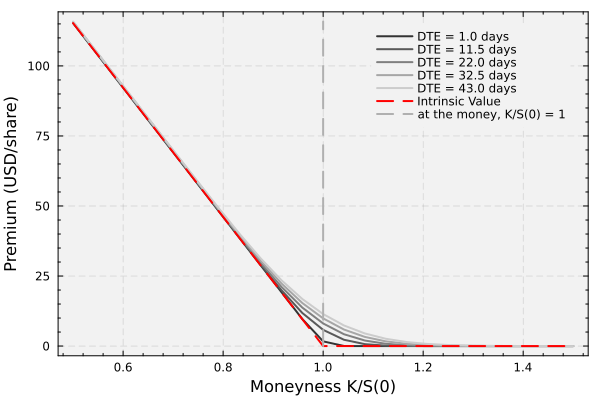

In [12]:
let

    # initialize -
    number_of_steps = 100;
    number_of_DTE_values = length(DTEV);
    colors = [RGB(0.2 + 0.6*(i-1)/(number_of_DTE_values-1), 0.2 + 0.6*(i-1)/(number_of_DTE_values-1), 0.2 + 0.6*(i-1)/(number_of_DTE_values-1)) for i in 1:number_of_DTE_values];

    # initialize -
    (number_of_strike_prices, number_of_DTE_values) = size(premium_matrix);
    fig = plot();
    for i ∈ 1:number_of_DTE_values
        DTE_value = DTEV[i];
        plot!(fig, SPV ./ Sₒ, premium_matrix[:,i], label="DTE = $(round(DTE_value, digits=1)) days", lw=2, c=colors[i]);
    end

    plot!(fig, intrinsic_array[:,1] ./ Sₒ, intrinsic_array[:,2], 
        label="Intrinsic Value", lw=2, ls=:dash, color=:red);

    # at-the-money line, K/S(0) = 1 -
    VLINE = zeros(number_of_steps, 2)
    VLINE[:,1] .= ones(number_of_steps)
    VLINE[:,2] .= range(0, stop = maximum(premium_matrix), length = number_of_steps) |> collect;
    plot!(VLINE[:,1], VLINE[:,2], lw=2, c= :gray69, ls=:dash, label="at the money, K/S(0) = 1")

    plot!(bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, 
        xminorticks=true, yminorticks=true, grid = :both, gridstyle = :dash, legend=:topright);  
    xlabel!(fig, "Moneyness K/S(0)");
    ylabel!(fig, "Premium (USD/share)");

    display(fig)

    # uncomment to save this figure -
    # savefig(fig, joinpath(_PATH_TO_FIGS, "CHEME-5660-L10a-Example-ExtrinsicValue-Fall-2026.svg"));
end

[The `argmin(...)` function](https://docs.julialang.org/en/v1/base/collections/#Base.argmin) finds the sweep strike prices nearest 0.8, 1.0, and 1.2 times the share price. Let's read their extrinsic value $E_{V}$ (USD/share) for the shortest and longest times to expiration:

In [13]:
let

    # initialize: the sweep strikes nearest 0.8Sₒ, Sₒ, and 1.2Sₒ -
    picks = [argmin(abs.(SPV .- f*Sₒ)) for f ∈ (0.8, 1.0, 1.2)];
    EVM = premium_matrix .- intrinsic_array[:,2]; # extrinsic value of every contract in the sweep (USD/share)

    df = DataFrame(
        strike         = round.(SPV[picks], digits = 2),
        moneyness      = round.(SPV[picks] ./ Sₒ, digits = 2), # K/S(0)
        intrinsic      = round.(intrinsic_array[picks,2], digits = 2),
        extrinsic_short = round.(EVM[picks,1], digits = 3),
        extrinsic_long  = round.(EVM[picks,end], digits = 3)
    );
    pretty_table(df;
        column_labels = ["strike K", "K/S(0)", "intrinsic value", "E_V at $(round(DTEV[1], digits=1)) days",
            "E_V at $(round(DTEV[end], digits=1)) days"],
        alignment = [:r, :r, :r, :r, :r], table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);

    # checks: extrinsic value is never negative, and the longer-dated contract carries at least as much -
    @assert all(EVM .≥ -1e-9) "a premium is below its intrinsic value"
    @assert all(EVM[:,end] .≥ EVM[:,1]) "a shorter-dated contract has more extrinsic value"
end

 ---------- -------- ----------------- ----------------- ------------------
  strike K   K/S(0)   intrinsic value   E_V at 1.0 days   E_V at 43.0 days 
 ---------- -------- ----------------- ----------------- ------------------
    182.53     0.79             48.04             0.021              1.079
    230.57      1.0               0.0             1.674             11.425
    278.61     1.21               0.0               0.0              0.761
 ---------- -------- ----------------- ----------------- ------------------


### Discussion
* __Hmmmm__. At the same strike price, long-dated contracts have higher premiums than short-dated ones, even though their intrinsic values are identical. Why?
* __Curious__. Why does a call's premium approach its intrinsic value far from the share price, both out of the money (high strike prices) and deep in the money (low strike prices)? Why does a small gap remain deep in the money?
___

## Summary
In this example, we split a call's premium into intrinsic and extrinsic value and measured how the extrinsic value changes with the time to expiration and the strike price.

> __Key Takeaways:__
>
> * __Extrinsic value represents time value:__ Extrinsic value is the premium minus the intrinsic value, the price of the chance that the share price moves our way before expiration. Our out-of-the-money call had zero intrinsic value, so its whole premium was extrinsic.
> * __Time decay affects extrinsic value:__ Longer-dated calls carried more extrinsic value than shorter-dated ones at the same strike price. More time gives the share price more room to move our way.
> * __Moneyness influences value decomposition:__ Calls near the money carried the most extrinsic value. Far from the share price, the premium approached the intrinsic value, and deep in the money only a small gap remained, at least the interest on the strike price.

The split shows how much of a premium pays for time, and that part decays as expiration nears.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___